# Method 2 versus Method 3: do they point at the same places?

Method 2 (structural survival and Mahalanobis distance from known UDUs) and Method 3 (cross-fitted UDU propensity) both rank parcels by how unlike reported UDUs they look. This notebook compares the two rankings at three levels: individual parcels, the potential non-UDU flags, and half-mile areas.

It reads the AIN-level scores that notebooks 02 and 03 save to `data/02_intermediate/method_scores/`. Rerun those notebooks first whenever the city outputs change, so both score files describe the same parcel universe.

In [1]:
from datetime import datetime
from pathlib import Path
import sqlite3
import sys

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.collections import PolyCollection

def find_project_root(start):
    start = Path(start).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / 'src').exists() and (candidate / 'data').exists():
            return candidate
    raise RuntimeError('Could not locate the NDSC_HiddenHousing project root')

PROJECT_ROOT = find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.viz import AIN_POINT_CRS, load_ain_points, plot_ain_hexbin

METHOD_SCORES_DIR = PROJECT_ROOT / 'data/02_intermediate/method_scores'
MASTER_DB = PROJECT_ROOT / 'data/01_source/all_parcel_data.sqlite'
CITY_BOUNDARY = PROJECT_ROOT / 'data/01_source/lacity_boundary.geojson'
CELL_FT = 2640  # half-mile cells for area-level statistics
MIN_CELL_AINS = 20

score_files = {
    'method1': METHOD_SCORES_DIR / 'method1_scores_2017.parquet',
    'method2': METHOD_SCORES_DIR / 'method2_scores_2017.parquet',
    'method3': METHOD_SCORES_DIR / 'method3_scores_2017.parquet',
}
missing = [str(path) for path in score_files.values() if not path.exists()]
if missing:
    raise FileNotFoundError('Run notebooks 01, 02 and 03 first; missing ' + ', '.join(missing))
method1_scores = pd.read_parquet(score_files['method1'])
method2_scores = pd.read_parquet(score_files['method2'])
method3_scores = pd.read_parquet(score_files['method3'])

def spearman(frame, a, b):
    return frame[a].corr(frame[b], method='spearman')

display(pd.DataFrame({
    'rows': [len(method1_scores), len(method2_scores), len(method3_scores)],
    'saved': [
        datetime.fromtimestamp(path.stat().st_mtime).strftime('%Y-%m-%d %H:%M')
        for path in score_files.values()
    ],
}, index=[path.name for path in score_files.values()]))

,rows,saved
method1_scores_2017.parquet,552796,2026-09-29 12:45
method2_scores_2017.parquet,552733,2026-09-29 12:46
method3_scores_2017.parquet,552733,2026-09-29 12:52


## A common scale

Method 2 scores only structurally stable, non-UDU parcels, so the comparison uses the parcels both methods score. Both scores are oriented so that **higher means less UDU-like**:

- Method 2: `method2_udu_distance_percentile`, the share of known UDUs of the same use type that are closer to the known-UDU profile.
- Method 3: one minus `method3_score_pct_rank_by_use_type`, using whichever model notebook 03 chose as final. The baseline and regularized variants are also compared.

Each score is then ranked within use type over this shared set, so both are uniform on [0, 1] and a median of 0.5 is the expectation.

In [2]:
both = method2_scores[[
    'AIN', 'SpecificUseType', 'is_known_udu', 'method2_structural_screen',
    'method2_udu_distance_percentile', 'method2_potential_nonudu',
]].merge(
    method3_scores[[
        'AIN', 'SpecificUseType', 'method3_final_model',
        'method3_score_pct_rank_by_use_type', 'method3_potential_nonudu',
        'method3_baseline_score_pct_rank_by_use_type',
        'method3_regularized_score_pct_rank_by_use_type',
    ]].rename(columns={'SpecificUseType': 'method3_use_type'}),
    on='AIN', how='inner', validate='one_to_one',
)
if both['SpecificUseType'].ne(both['method3_use_type']).any():
    raise ValueError('Methods 2 and 3 disagree on SpecificUseType for some AINs')

eligible = both.loc[~both['is_known_udu']].copy()
shared = eligible.loc[
    eligible['method2_structural_screen']
    & eligible['method2_udu_distance_percentile'].notna()
].copy()
shared['method2_nonudu'] = shared['method2_udu_distance_percentile']
for model, column in [
    ('method3', 'method3_score_pct_rank_by_use_type'),
    ('method3_baseline', 'method3_baseline_score_pct_rank_by_use_type'),
    ('method3_regularized', 'method3_regularized_score_pct_rank_by_use_type'),
]:
    shared[f'{model}_nonudu'] = 1 - shared[column]
for model in ['method2', 'method3', 'method3_baseline', 'method3_regularized']:
    shared[f'{model}_rank'] = (
        shared.groupby('SpecificUseType')[f'{model}_nonudu']
        .rank(method='average', pct=True)
    )

display(pd.Series({
    'AINs scored by both notebooks': len(both),
    'shared structural candidates (non-UDU)': len(shared),
    'Method 3 final model': both['method3_final_model'].iloc[0],
    'Spearman: Method 2 vs Method 3 final': spearman(shared, 'method2_rank', 'method3_rank'),
    'Spearman: Method 2 vs Method 3 baseline': spearman(shared, 'method2_rank', 'method3_baseline_rank'),
    'Spearman: Method 2 vs Method 3 regularized': spearman(shared, 'method2_rank', 'method3_regularized_rank'),
    'Spearman: Method 3 baseline vs regularized': spearman(shared, 'method3_baseline_rank', 'method3_regularized_rank'),
}, name='value').to_frame())
display(
    shared.groupby('SpecificUseType')
    .apply(lambda group: pd.Series({
        'shared candidates': len(group),
        'Spearman Method 2 vs 3': spearman(group, 'method2_nonudu', 'method3_nonudu'),
        'Method 2 flag share': group['method2_potential_nonudu'].mean(),
        'Method 3 flag share': group['method3_potential_nonudu'].mean(),
    }), include_groups=False)
    .sort_values('shared candidates', ascending=False)
    .round(3)
)

,value
AINs scored by both notebooks,552733
shared structural candidates (non-UDU),202044
Method 3 final model,baseline
Spearman: Method 2 vs Method 3 final,0.02185
Spearman: Method 2 vs Method 3 baseline,0.02185
Spearman: Method 2 vs Method 3 regularized,-0.02892
Spearman: Method 3 baseline vs regularized,0.979951


,shared candidates,Spearman Method 2 vs 3,Method 2 flag share,Method 3 flag share
SpecificUseType,,,,
Single Family Residence,117236.0,-0.078,0.048,0.021
Five or More Units or Apartments (Any Combination),29104.0,0.185,0.111,0.042
"Double, Duplex, or Two Units",28919.0,0.106,0.035,0.046
Four Units (Any Combination),12761.0,0.131,0.059,0.044
Three Units (Any Combination),11811.0,0.241,0.028,0.041
Store Combination,2213.0,0.138,0.138,0.037


## Flag agreement

Among the shared candidates, the only parcels Method 2 can flag, how often do both methods flag the same parcel? Lift compares the observed overlap with what independent flags would produce. The second table covers every eligible non-UDU parcel, since Method 3 also flags parcels that fail Method 2's structural screen.

In [3]:
flag2 = shared['method2_potential_nonudu']
flag3 = shared['method3_potential_nonudu']
display(pd.crosstab(
    flag2.rename('Method 2 flag'), flag3.rename('Method 3 flag'), margins=True
))
display(pd.Series({
    'flagged by both': int((flag2 & flag3).sum()),
    'Jaccard overlap': (flag2 & flag3).sum() / (flag2 | flag3).sum(),
    'lift over independence': (flag2 & flag3).mean() / (flag2.mean() * flag3.mean()),
    'P(Method 3 flag | Method 2 flag)': flag3[flag2].mean(),
    'P(Method 3 flag | no Method 2 flag)': flag3[~flag2].mean(),
}, name='shared candidates').to_frame())

all2 = eligible['method2_potential_nonudu']
all3 = eligible['method3_potential_nonudu']
display(pd.Series({
    'Method 2 flags': int(all2.sum()),
    'Method 3 flags': int(all3.sum()),
    'flagged by both': int((all2 & all3).sum()),
    'Jaccard overlap': (all2 & all3).sum() / (all2 | all3).sum(),
    'Method 3 flags failing the Method 2 structural screen': int(
        (all3 & ~eligible['method2_structural_screen']).sum()
    ),
}, name='all eligible non-UDU AINs').to_frame())

Method 3 flag,False,True,All
Method 2 flag,,,
False,185289,5508,190797
True,10550,697,11247
All,195839,6205,202044


,shared candidates
flagged by both,697.000000
Jaccard overlap,0.041600
lift over independence,2.017903
P(Method 3 flag | Method 2 flag),0.061972
P(Method 3 flag | no Method 2 flag),0.028868


,all eligible non-UDU AINs
Method 2 flags,11247.000000
Method 3 flags,27619.000000
flagged by both,697.000000
Jaccard overlap,0.018261
Method 3 flags failing the Method 2 structural screen,21414.000000


## Area-level agreement

Parcels are grouped into half-mile squares (`CELL_FT`), keeping cells with at least `MIN_CELL_AINS` shared candidates. Each cell gets the median rank from each method. A positive correlation across cells means both methods treat the same areas as less UDU-like. The top-cell overlap is compared with its chance value.

In [4]:
points = load_ain_points()
shared = shared.merge(points, on='AIN', how='left', validate='one_to_one')
located = shared.loc[shared['x'].notna()].copy()
located['cell_x'] = np.floor(located['x'] / CELL_FT).astype(int)
located['cell_y'] = np.floor(located['y'] / CELL_FT).astype(int)
cells = located.groupby(['cell_x', 'cell_y']).agg(
    ains=('AIN', 'size'),
    method2=('method2_rank', 'median'),
    method3=('method3_rank', 'median'),
    method3_regularized=('method3_regularized_rank', 'median'),
    method2_flag_share=('method2_potential_nonudu', 'mean'),
    method3_flag_share=('method3_potential_nonudu', 'mean'),
).reset_index()
cells = cells.loc[cells['ains'].ge(MIN_CELL_AINS)].reset_index(drop=True)

area_summary = {
    'shared candidates with a center point': len(located),
    'half-mile cells kept': len(cells),
    'cell Spearman: median ranks, Method 2 vs 3': spearman(cells, 'method2', 'method3'),
    'cell Spearman: median ranks, Method 2 vs 3 regularized': spearman(cells, 'method2', 'method3_regularized'),
    'cell Spearman: flag shares': spearman(cells, 'method2_flag_share', 'method3_flag_share'),
}
# Method 2 cell medians tie heavily, so take exactly the top share of cells.
for share in [0.2, 0.1]:
    top_count = round(share * len(cells))
    top2 = cells['method2'].rank(method='first', ascending=False).le(top_count)
    top3 = cells['method3'].rank(method='first', ascending=False).le(top_count)
    area_summary[f'top {share:.0%} cells shared (chance ≈ {share * top2.sum():.0f})'] = (
        f'{int((top2 & top3).sum())} of {int(top2.sum())}'
    )
display(pd.Series(area_summary, name='value').to_frame())

cells['method2_tertile'] = pd.qcut(cells['method2'].rank(method='first'), 3, labels=False)
cells['method3_tertile'] = pd.qcut(cells['method3'].rank(method='first'), 3, labels=False)
display(
    pd.crosstab(cells['method2_tertile'], cells['method3_tertile'])
    .rename_axis(index='Method 2 tertile (low → high)', columns='Method 3 tertile (low → high)')
)

,value
shared candidates with a center point,202044
half-mile cells kept,1285
"cell Spearman: median ranks, Method 2 vs 3",-0.282271
"cell Spearman: median ranks, Method 2 vs 3 regularized",-0.360629
cell Spearman: flag shares,0.090472
top 20% cells shared (chance ≈ 51),25 of 257
top 10% cells shared (chance ≈ 13),2 of 128


Method 3 tertile (low → high),0,1,2
Method 2 tertile (low → high),,,
0,82,209,138
1,130,143,155
2,217,76,135


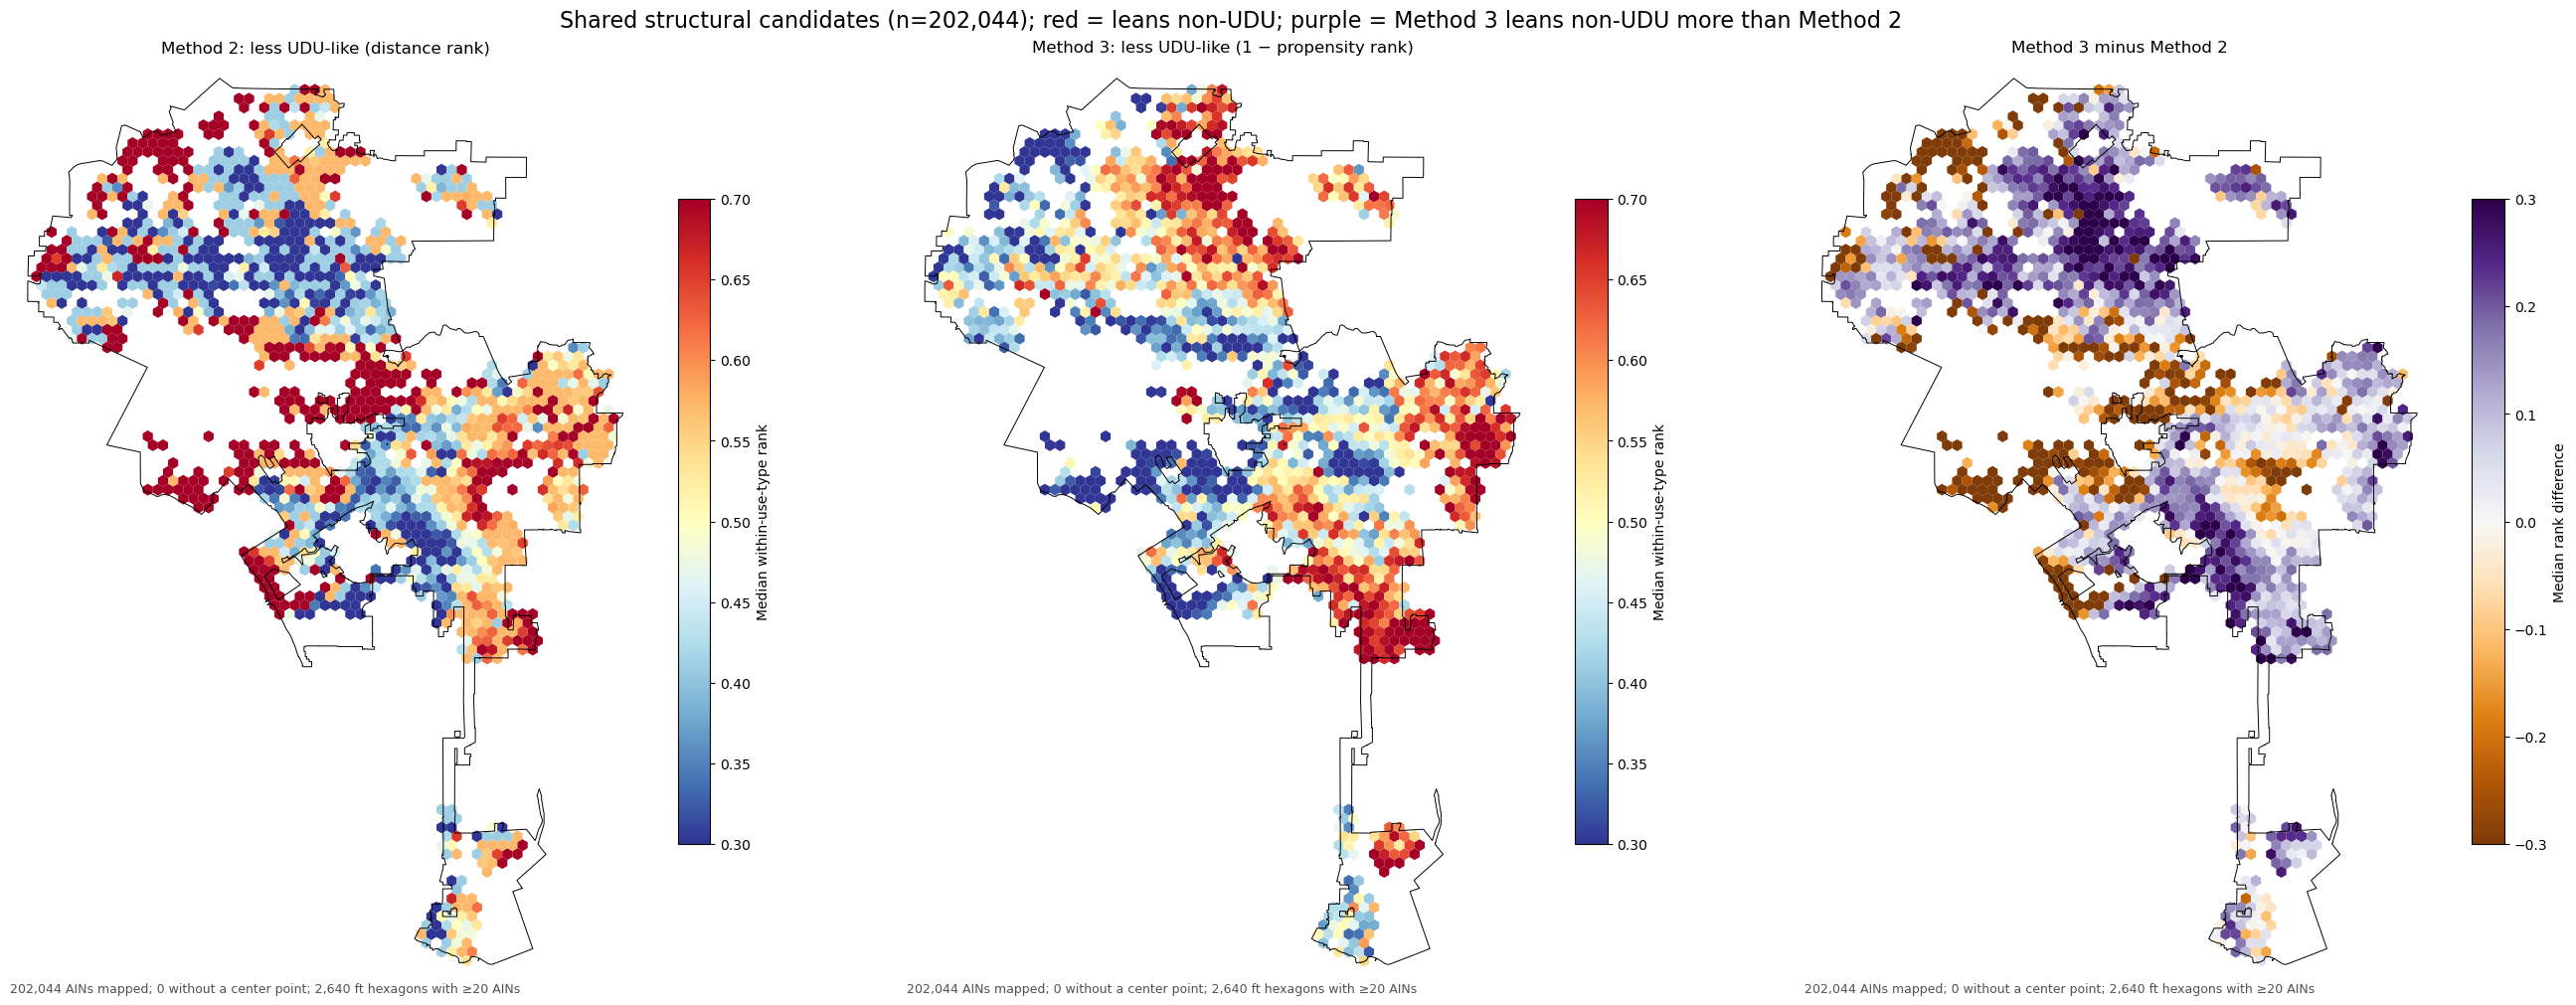

In [5]:
boundary = gpd.read_file(CITY_BOUNDARY).to_crs(AIN_POINT_CRS)
minx, miny, maxx, maxy = boundary.total_bounds
pad = 0.02 * max(maxx - minx, maxy - miny)

def frame_city(ax):
    boundary.boundary.plot(ax=ax, color='k', linewidth=0.7)
    ax.set_xlim(minx - pad, maxx + pad)
    ax.set_ylim(miny - pad, maxy + pad)
    ax.set_aspect('equal')
    ax.set_axis_off()

located['rank_difference'] = located['method3_rank'] - located['method2_rank']
map_points = located[['AIN', 'x', 'y']]
fig, axes = plt.subplots(1, 3, figsize=(27, 10), constrained_layout=True)
for ax, column, cmap, vmin, vmax, title, label in [
    (axes[0], 'method2_rank', 'RdYlBu_r', 0.3, 0.7,
     'Method 2: less UDU-like (distance rank)', 'Median within-use-type rank'),
    (axes[1], 'method3_rank', 'RdYlBu_r', 0.3, 0.7,
     'Method 3: less UDU-like (1 − propensity rank)', 'Median within-use-type rank'),
    (axes[2], 'rank_difference', 'PuOr', -0.3, 0.3,
     'Method 3 minus Method 2', 'Median rank difference'),
]:
    plot_ain_hexbin(
        located, column, points=map_points, ax=ax, hex_width_ft=CELL_FT,
        min_count=MIN_CELL_AINS, cmap=cmap, vmin=vmin, vmax=vmax,
        title=title, colorbar_label=label,
    )
    frame_city(ax)
fig.suptitle(
    f'Shared structural candidates (n={len(located):,}); red = leans non-UDU; '
    'purple = Method 3 leans non-UDU more than Method 2',
    fontsize=16,
)
plt.show()

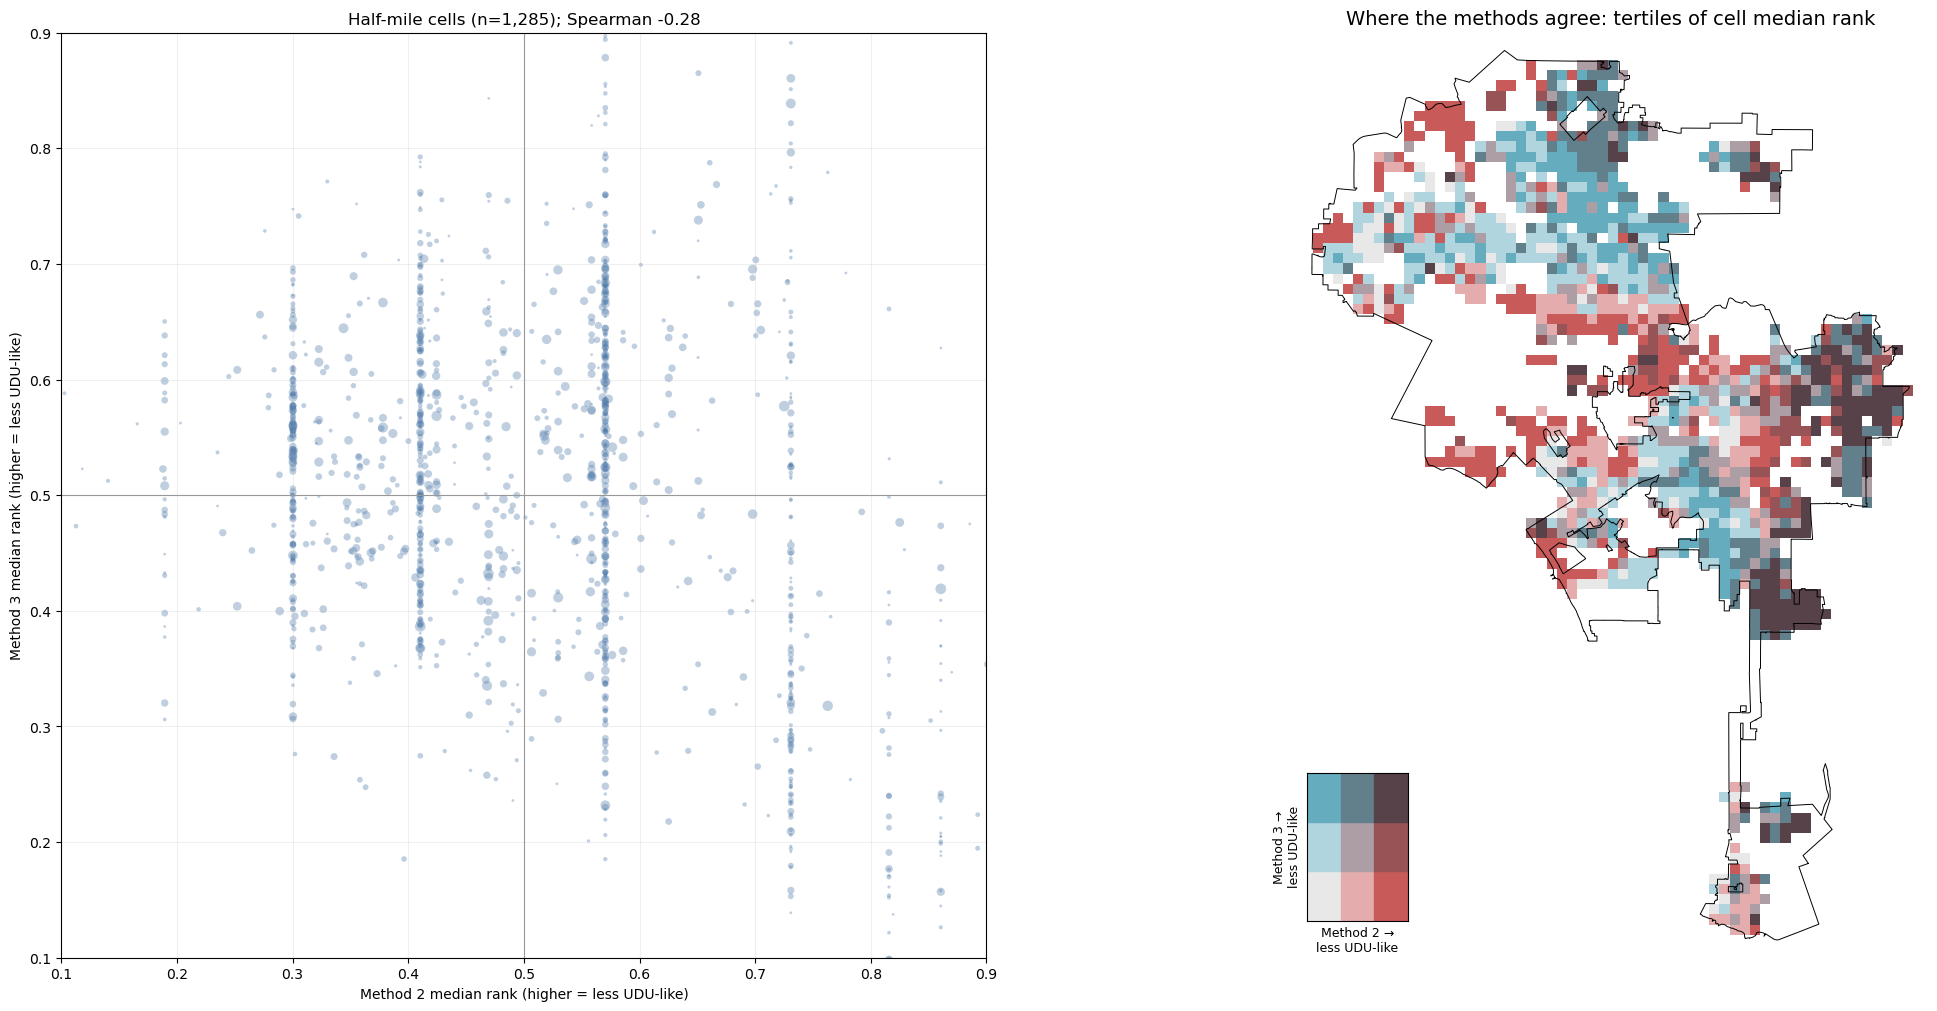

In [6]:
# Bivariate palette: rows are Method 2 tertiles, columns Method 3 tertiles.
BIVARIATE = np.array([
    ['#e8e8e8', '#b0d5df', '#64acbe'],
    ['#e4acac', '#ad9ea5', '#627f8c'],
    ['#c85a5a', '#985356', '#574249'],
])
fig, axes = plt.subplots(
    1, 2, figsize=(22, 10), constrained_layout=True,
    gridspec_kw={'width_ratios': [1, 1.25]},
)
ax = axes[0]
ax.scatter(
    cells['method2'], cells['method3'], s=np.clip(cells['ains'] / 8, 4, 60),
    alpha=0.35, color='#4c78a8', linewidths=0,
)
ax.axhline(0.5, color='#999999', linewidth=0.8)
ax.axvline(0.5, color='#999999', linewidth=0.8)
ax.set(
    xlim=(0.1, 0.9), ylim=(0.1, 0.9), aspect='equal',
    xlabel='Method 2 median rank (higher = less UDU-like)',
    ylabel='Method 3 median rank (higher = less UDU-like)',
    title=f"Half-mile cells (n={len(cells):,}); Spearman {spearman(cells, 'method2', 'method3'):.2f}",
)
ax.grid(alpha=0.2)

ax = axes[1]
squares = [
    [(x * CELL_FT, y * CELL_FT), ((x + 1) * CELL_FT, y * CELL_FT),
     ((x + 1) * CELL_FT, (y + 1) * CELL_FT), (x * CELL_FT, (y + 1) * CELL_FT)]
    for x, y in zip(cells['cell_x'], cells['cell_y'])
]
ax.add_collection(PolyCollection(
    squares, facecolors=BIVARIATE[cells['method2_tertile'], cells['method3_tertile']],
    edgecolors='none',
))
frame_city(ax)
ax.set_title('Where the methods agree: tertiles of cell median rank', fontsize=14)
key = ax.inset_axes([0.02, 0.04, 0.16, 0.16])
for row in range(3):
    for column in range(3):
        key.add_patch(plt.Rectangle((row, column), 1, 1, color=BIVARIATE[row, column]))
key.set(xlim=(0, 3), ylim=(0, 3), xticks=[], yticks=[])
key.set_xlabel('Method 2 →\nless UDU-like', fontsize=9)
key.set_ylabel('Method 3 →\nless UDU-like', fontsize=9)
plt.show()

## What drives the difference?

Land value is Method 3's strongest SHAP feature, and Mahalanobis distance rewards parcels that are unusual in any direction. The table relates each method's rank to the 2016 assessor land value and building area, both ranked within use type. "Land-value extremeness" is the distance of that rank from the median. The last line asks whether the areas still disagree once land value is held fixed.

In [7]:
with sqlite3.connect(MASTER_DB) as connection:
    assessor_2016 = pd.read_sql_query(
        'SELECT AssessorID, roll_landvalue_2016, sqftmain_2016 FROM all_parcel_data',
        connection,
    )
assessor_2016['AIN'] = assessor_2016['AssessorID'].str.replace('-', '', regex=False)
drivers = located.merge(
    assessor_2016[['AIN', 'roll_landvalue_2016', 'sqftmain_2016']],
    on='AIN', how='left', validate='one_to_one',
)
drivers['land_value'] = drivers['roll_landvalue_2016'].where(drivers['roll_landvalue_2016'].gt(0))
drivers['land_value_rank'] = drivers.groupby('SpecificUseType')['land_value'].rank(pct=True)
drivers['building_sqft_rank'] = drivers.groupby('SpecificUseType')['sqftmain_2016'].rank(pct=True)
drivers['land_value_extremeness'] = (drivers['land_value_rank'] - 0.5).abs()

display(pd.DataFrame({
    method: {
        driver: spearman(drivers, f'{method}_rank', driver)
        for driver in ['land_value_rank', 'building_sqft_rank', 'land_value_extremeness']
    }
    for method in ['method2', 'method3']
}).rename(columns={'method2': 'Method 2', 'method3': 'Method 3'}).round(3))

cell_drivers = drivers.groupby(['cell_x', 'cell_y']).agg(
    ains=('AIN', 'size'), method2=('method2_rank', 'median'),
    method3=('method3_rank', 'median'), land=('land_value_rank', 'median'),
)
cell_drivers = cell_drivers.loc[cell_drivers['ains'].ge(MIN_CELL_AINS)]

def residual_ranks(values, control):
    values, control = values.rank().to_numpy(), control.rank().to_numpy()
    return values - np.polyval(np.polyfit(control, values, 1), control)

display(pd.Series({
    'cell Spearman: Method 2 vs median land value': spearman(cell_drivers, 'method2', 'land'),
    'cell Spearman: Method 3 vs median land value': spearman(cell_drivers, 'method3', 'land'),
    'cell Method 2 vs 3, land value held fixed (partial rank correlation)': np.corrcoef(
        residual_ranks(cell_drivers['method2'], cell_drivers['land']),
        residual_ranks(cell_drivers['method3'], cell_drivers['land']),
    )[0, 1],
    'distinct Method 2 percentiles among single-family candidates': shared.loc[
        shared['SpecificUseType'].eq('Single Family Residence'),
        'method2_udu_distance_percentile',
    ].nunique(),
}, name='value').to_frame().round(3))

,Method 2,Method 3
land_value_rank,0.014,-0.554
building_sqft_rank,0.208,-0.460
land_value_extremeness,0.235,0.112


,value
cell Spearman: Method 2 vs median land value,0.225
cell Spearman: Method 3 vs median land value,-0.718
"cell Method 2 vs 3, land value held fixed (partial rank correlation)",-0.178
distinct Method 2 percentiles among single-family candidates,14.000


## All three methods in one table

`all_methods` has one row per AIN scored by any method (an outer join). Each method contributes its final flag, `methodN_potential_nonudu` (the value in its `methodN_output`), followed by its sub-metrics, each with its own score and flag. A flag is missing (`<NA>`) where a method did not score the AIN, which is different from `False`.

| method and sub-metric | columns | score direction and flag rule |
|---|---|---|
| Method 1 residual screen (final) | `method1_residual_sqft`, `method1_residual_score`, `method1_residual_potential_nonudu` | within-use-type rank of \|LARIAC floor area − SQFTmain\|; **low = close agreement**; bottom 2.5% with a positive residual |
| Method 1 ratio screen | `method1_ratio`, `method1_ratio_score`, `method1_ratio_potential_nonudu` | within-use-type rank of LARIAC floor area / SQFTmain; **low = assessor records at least as much area**; bottom 5% |
| Method 2 structural screen | `method2_structural_screen`, `method2_check_*` | each stability check, and whether all passed |
| Method 2 UDU similarity (final) | `method2_distance`, `method2_distance_score`, `method2_udu_like`, `method2_status` | share of known UDUs closer to the UDU profile; **high = less UDU-like**; passes the screen and lies beyond the known-UDU 90th percentile |
| Method 3 tract-matched baseline | `method3_baseline_score`, `method3_baseline_rank`, `method3_baseline_potential_nonudu` | UDU propensity; **high = more UDU-like**; bottom 5% within use type |
| Method 3 regularized | `method3_regularized_*` | as the baseline |
| Method 3 land-value-matched | `method3_landvalue_*`, `method3_landvalue_band_rank` | as the baseline, but flagged in the bottom 5% within use type × land-value band |

`method3_final_model` records which Method 3 model supplies `method3_potential_nonudu`. `methods_flagging` counts the three final flags that are true, and `all_methods_potential_nonudu` is true only where every method scored and flagged the AIN.

In [8]:
METHOD1_COLUMNS = {
    'raw_residual_sqft': 'method1_residual_sqft',
    'abs_residual_pct_rank_by_use_type': 'method1_residual_score',
    'method1_potential_nonudu': 'method1_residual_potential_nonudu',
    'floor_area_to_sqft_ratio': 'method1_ratio',
    'ratio_pct_rank_by_use_type': 'method1_ratio_score',
    'method1_ratio_potential_nonudu': 'method1_ratio_potential_nonudu',
}
METHOD2_COLUMNS = {
    'SpecificUseType': 'method2_use_type',
    'is_known_udu': 'method2_known_udu',
    'method2_potential_nonudu': 'method2_potential_nonudu',
    'method2_structural_screen': 'method2_structural_screen',
    **{
        column: f'method2_{column}'
        for column in method2_scores.columns if column.startswith('check_')
    },
    'method2_mahalanobis_distance': 'method2_distance',
    'method2_udu_distance_percentile': 'method2_distance_score',
    'method2_udu_like': 'method2_udu_like',
    'method2_status': 'method2_status',
}
METHOD3_COLUMNS = {
    'SpecificUseType': 'method3_use_type',
    'is_known_udu': 'method3_known_udu',
    'method3_landvalue_band': 'LandValueBand',
    'method3_potential_nonudu': 'method3_potential_nonudu',
    'method3_final_model': 'method3_final_model',
    **{
        f'method3_{model}_{source}': f'method3_{model}_{target}'
        for model in ['baseline', 'regularized', 'landvalue']
        for source, target in [
            ('udu_score', 'score'),
            ('score_pct_rank_by_use_type', 'rank'),
            ('potential_nonudu', 'potential_nonudu'),
        ]
    },
    'method3_landvalue_score_pct_rank_by_band': 'method3_landvalue_band_rank',
}
FINAL_FLAGS = [
    'method1_potential_nonudu', 'method2_potential_nonudu', 'method3_potential_nonudu',
]

all_methods = (
    method3_scores[['AIN', *METHOD3_COLUMNS]].rename(columns=METHOD3_COLUMNS)
    .merge(
        method2_scores[['AIN', *METHOD2_COLUMNS]].rename(columns=METHOD2_COLUMNS),
        on='AIN', how='outer', validate='one_to_one',
    )
    .merge(
        method1_scores[['AIN', *METHOD1_COLUMNS]].rename(columns=METHOD1_COLUMNS),
        on='AIN', how='outer', validate='one_to_one',
    )
)
# Method 1 publishes its residual screen as its final flag (method1_output).
all_methods['method1_potential_nonudu'] = all_methods['method1_residual_potential_nonudu']
all_methods['UseType'] = all_methods['method3_use_type'].fillna(all_methods['method2_use_type'])
all_methods['KnownUDU'] = all_methods['method3_known_udu'].fillna(all_methods['method2_known_udu'])
all_methods['LandValueBand'] = all_methods['LandValueBand'].astype('Int64')
boolean_columns = [
    column for column in all_methods.columns
    if column.endswith(('potential_nonudu', 'structural_screen', 'udu_like'))
    or column.startswith('method2_check_') or column == 'KnownUDU'
]
all_methods[boolean_columns] = all_methods[boolean_columns].astype('boolean')
all_methods['methods_scoring'] = all_methods[FINAL_FLAGS].notna().sum(axis=1)
all_methods['methods_flagging'] = all_methods[FINAL_FLAGS].fillna(False).sum(axis=1)
all_methods['all_methods_potential_nonudu'] = all_methods['methods_flagging'].eq(len(FINAL_FLAGS))

identity = {'method2_use_type', 'method2_known_udu', 'method3_use_type', 'method3_known_udu', 'LandValueBand'}
all_methods = all_methods[[
    'AIN', 'UseType', 'LandValueBand', 'KnownUDU',
    'method1_potential_nonudu', *METHOD1_COLUMNS.values(),
    *[column for column in METHOD2_COLUMNS.values() if column not in identity],
    *[column for column in METHOD3_COLUMNS.values() if column not in identity],
    'methods_scoring', 'methods_flagging', 'all_methods_potential_nonudu',
]].sort_values('AIN').reset_index(drop=True)

with pd.option_context('display.max_columns', None):
    display(all_methods.head(10))
    display(all_methods.loc[all_methods['all_methods_potential_nonudu']].head(10))

,AIN,UseType,LandValueBand,KnownUDU,method1_potential_nonudu,method1_residual_sqft,method1_residual_score,method1_residual_potential_nonudu,method1_ratio,method1_ratio_score,method1_ratio_potential_nonudu,method2_potential_nonudu,method2_structural_screen,method2_check_eligible_snapshot,method2_check_no_structural_change,method2_check_assessor_stable,method2_check_lot_size,method2_check_building_count,method2_check_floor_area_ratio,method2_distance,method2_distance_score,method2_udu_like,method2_status,method3_potential_nonudu,method3_final_model,method3_baseline_score,method3_baseline_rank,method3_baseline_potential_nonudu,method3_regularized_score,method3_regularized_rank,method3_regularized_potential_nonudu,method3_landvalue_score,method3_landvalue_rank,method3_landvalue_potential_nonudu,method3_landvalue_band_rank,methods_scoring,methods_flagging,all_methods_potential_nonudu
0,2004001003,Single Family Residence,8,False,False,6599.54,0.974808,False,4.157675,0.983725,False,False,False,True,True,True,True,False,False,NaN,NaN,False,not_structurally_stable,False,baseline,0.086240,0.173928,False,0.179496,0.261269,False,0.032019,0.023227,True,0.026644,3,0,False
1,2004001004,Single Family Residence,6,False,False,2903.04,0.814827,False,2.171053,0.715469,False,False,True,True,True,True,True,True,True,5.157023,0.642857,True,udu_like,False,baseline,0.477728,0.958215,False,0.567296,0.964675,False,0.187814,0.712395,False,0.696374,3,0,False
2,2004001005,Single Family Residence,3,False,False,5172.18,0.950936,False,3.514429,0.95791,False,False,False,True,True,True,True,True,False,NaN,NaN,False,not_structurally_stable,False,baseline,0.347788,0.828087,False,0.449819,0.838610,False,0.155907,0.606776,False,0.625632,3,0,False
3,2004001008,Single Family Residence,3,False,False,3759.52,0.892208,False,2.551597,0.815054,False,False,False,True,True,True,False,False,False,NaN,NaN,False,not_structurally_stable,False,baseline,0.071608,0.116663,False,0.150813,0.178739,False,0.036149,0.036314,True,0.031002,3,0,False
4,2004001009,Single Family Residence,2,False,False,3791.58,0.894266,False,2.703315,0.84618,False,False,False,True,False,True,False,True,False,NaN,NaN,False,not_structurally_stable,False,baseline,0.287801,0.731621,False,0.438513,0.821410,False,0.112489,0.415837,False,0.446554,3,0,False
5,2004001010,Single Family Residence,2,False,False,3346.88,0.859779,False,2.381296,0.77575,False,False,False,True,True,True,False,True,True,NaN,NaN,False,not_structurally_stable,False,baseline,0.259734,0.678198,False,0.418053,0.789266,False,0.129075,0.494694,False,0.533576,3,0,False
6,2004001011,Single Family Residence,2,False,False,5442.08,0.95712,False,3.246009,0.932106,False,False,False,True,True,True,False,True,False,NaN,NaN,False,not_structurally_stable,False,baseline,0.251100,0.661113,False,0.426584,0.802956,False,0.165333,0.640704,False,0.688132,3,0,False
7,2004001012,Single Family Residence,5,False,False,2680.27,0.788693,False,2.204075,0.726178,False,False,False,True,True,True,False,True,True,NaN,NaN,False,not_structurally_stable,False,baseline,0.248635,0.655872,False,0.415410,0.784688,False,0.052683,0.106483,False,0.104383,3,0,False
8,2004001013,Single Family Residence,4,False,False,6100.71,0.968592,False,3.594943,0.963293,False,False,False,True,True,True,False,True,False,NaN,NaN,False,not_structurally_stable,False,baseline,0.321945,0.789392,False,0.440662,0.824821,False,0.125753,0.479273,False,0.460215,3,0,False
9,2004001014,Single Family Residence,5,False,False,5224.49,0.952245,False,3.156207,0.920571,False,False,False,True,True,True,False,True,False,NaN,NaN,False,not_structurally_stable,False,baseline,0.280083,0.717306,False,0.480672,0.881188,False,0.150200,0.584396,False,0.563774,3,0,False


,AIN,UseType,LandValueBand,KnownUDU,method1_potential_nonudu,method1_residual_sqft,method1_residual_score,method1_residual_potential_nonudu,method1_ratio,method1_ratio_score,method1_ratio_potential_nonudu,method2_potential_nonudu,method2_structural_screen,method2_check_eligible_snapshot,method2_check_no_structural_change,method2_check_assessor_stable,method2_check_lot_size,method2_check_building_count,method2_check_floor_area_ratio,method2_distance,method2_distance_score,method2_udu_like,method2_status,method3_potential_nonudu,method3_final_model,method3_baseline_score,method3_baseline_rank,method3_baseline_potential_nonudu,method3_regularized_score,method3_regularized_rank,method3_regularized_potential_nonudu,method3_landvalue_score,method3_landvalue_rank,method3_landvalue_potential_nonudu,method3_landvalue_band_rank,methods_scoring,methods_flagging,all_methods_potential_nonudu
137142,2414001035,Five or More Units or Apartments (Any Combinat...,1,False,True,152.55,0.021464,True,1.086775,0.143413,False,True,True,True,True,True,True,True,True,5.317754,0.938144,False,potential_nonudu,True,baseline,0.072070,0.039409,True,0.123435,0.037691,True,0.126144,0.126599,False,0.239164,3,3,True
137560,2414016020,Single Family Residence,4,False,True,96.16,0.011298,True,1.267111,0.067675,False,True,True,True,True,True,True,True,True,8.086210,0.857143,False,potential_nonudu,True,baseline,0.050108,0.044024,True,0.118980,0.095491,False,0.028629,0.014843,True,0.011945,3,3,True
158709,2546004005,Single Family Residence,1,False,True,74.76,0.008468,True,1.196737,0.047315,True,True,True,True,True,True,True,True,True,8.160307,0.857143,False,potential_nonudu,True,baseline,0.036387,0.013656,True,0.096999,0.049986,True,0.035607,0.034386,True,0.035382,3,3,True
248019,4006018019,Three Units (Any Combination),2,False,True,26.5,0.004453,True,1.006254,0.049336,True,True,True,True,True,True,True,True,True,5.012004,0.897436,False,potential_nonudu,True,baseline,0.059873,0.029902,True,0.112327,0.040153,True,0.070489,0.027004,True,0.043171,3,3,True
263798,4220016021,"Double, Duplex, or Two Units",8,False,True,33.43,0.007267,True,1.033768,0.045759,True,True,True,True,True,True,True,True,True,5.199693,0.936170,False,potential_nonudu,True,baseline,0.053155,0.029441,True,0.109546,0.050971,False,0.064575,0.031000,True,0.022263,3,3,True
265796,4225006012,Five or More Units or Apartments (Any Combinat...,5,False,True,159.82,0.022538,True,1.081209,0.138814,False,True,True,True,True,True,True,True,True,6.282679,0.984536,False,potential_nonudu,True,baseline,0.050085,0.013310,True,0.138619,0.055786,False,0.064229,0.020517,True,0.016600,3,3,True
270389,4235029016,"Double, Duplex, or Two Units",2,False,True,97.42,0.023269,True,1.088163,0.068409,False,True,True,True,True,True,True,True,True,5.338995,0.946809,False,potential_nonudu,True,baseline,0.061662,0.046798,True,0.108485,0.049160,True,0.120617,0.165203,False,0.225843,3,3,True
270992,4237004014,Five or More Units or Apartments (Any Combinat...,1,False,True,173.96,0.024562,True,1.050688,0.117625,False,True,True,True,True,True,True,True,True,8.709289,1.000000,False,potential_nonudu,True,baseline,0.060754,0.024381,True,0.099030,0.016193,True,0.059827,0.015641,True,0.035967,3,3,True
271007,4237005004,Five or More Units or Apartments (Any Combinat...,10,False,True,103.29,0.014749,True,1.029758,0.103857,False,True,True,True,True,True,True,True,True,6.523719,0.989691,False,potential_nonudu,True,baseline,0.069609,0.035882,True,0.152088,0.073880,False,0.026052,0.000215,True,0.000615,3,3,True
304719,4357002009,Single Family Residence,7,False,True,49.52,0.005409,True,1.1238,0.03173,True,True,True,True,True,True,True,True,True,7.982958,0.857143,False,potential_nonudu,True,baseline,0.047304,0.036603,True,0.109611,0.074515,False,0.034183,0.029687,True,0.032853,3,3,True


In [9]:
import itertools

in_all = all_methods.loc[all_methods['methods_scoring'].eq(len(FINAL_FLAGS))]
final_all = in_all['all_methods_potential_nonudu']
final_shares = in_all[FINAL_FLAGS].astype(float).mean()
display(pd.Series({
    'AINs scored by any method': len(all_methods),
    'AINs scored by all three methods': len(in_all),
    'AINs scored by one or two methods only': int(all_methods['methods_scoring'].lt(3).sum()),
    **{f'{flag} share': final_shares[flag] for flag in FINAL_FLAGS},
    'AINs flagged by all three (final flags)': int(final_all.sum()),
    'share flagged by all three (of AINs scored by all three)': final_all.mean(),
    'share flagged by all three (of all AINs)': final_all.sum() / len(all_methods),
    'share expected if the flags were independent': final_shares.prod(),
}, name='final flags').to_frame())
display(
    in_all['methods_flagging'].value_counts().sort_index()
    .rename('AINs').to_frame()
    .assign(share=lambda frame: frame['AINs'] / frame['AINs'].sum())
    .rename_axis('final flags true')
)

# Every combination of one sub-metric flag per method.
SUBMETRIC_FLAGS = {
    'Method 1': {
        'residual': 'method1_residual_potential_nonudu',
        'ratio': 'method1_ratio_potential_nonudu',
    },
    'Method 2': {'similarity': 'method2_potential_nonudu'},
    'Method 3': {
        'baseline': 'method3_baseline_potential_nonudu',
        'regularized': 'method3_regularized_potential_nonudu',
        'land value': 'method3_landvalue_potential_nonudu',
    },
}
combinations = []
for labels in itertools.product(*(options.keys() for options in SUBMETRIC_FLAGS.values())):
    columns = [SUBMETRIC_FLAGS[method][label] for method, label in zip(SUBMETRIC_FLAGS, labels)]
    flags = in_all[columns].fillna(False)
    all_true = flags.all(axis=1)
    combinations.append({
        **dict(zip(SUBMETRIC_FLAGS, labels)),
        'AINs flagged by all three': int(all_true.sum()),
        'share of AINs scored by all three': all_true.mean(),
        'expected if independent': flags.astype(float).mean().prod(),
    })
display(pd.DataFrame(combinations).sort_values('AINs flagged by all three', ascending=False))
display(
    in_all.groupby('UseType').agg(
        ains=('AIN', 'size'),
        flagged_by_all_three=('all_methods_potential_nonudu', 'sum'),
    )
    .assign(share=lambda frame: frame['flagged_by_all_three'] / frame['ains'])
    .sort_values('ains', ascending=False)
)

,final flags
AINs scored by any method,552796.000000
AINs scored by all three methods,552733.000000
AINs scored by one or two methods only,63.000000
method1_potential_nonudu share,0.019809
method2_potential_nonudu share,0.020348
method3_potential_nonudu share,0.049968
AINs flagged by all three (final flags),61.000000
share flagged by all three (of AINs scored by all three),0.000110
share flagged by all three (of all AINs),0.000110
share expected if the flags were independent,0.000020


,AINs,share
final flags true,,
0,504777,0.913238
1,46158,0.083509
2,1737,0.003143
3,61,0.00011


,Method 1,Method 2,Method 3,AINs flagged by all three,share of AINs scored by all three,expected if independent
3,ratio,similarity,baseline,103,0.000186,0.000051
4,ratio,similarity,regularized,87,0.000157,0.000051
2,residual,similarity,land value,74,0.000134,0.000020
5,ratio,similarity,land value,63,0.000114,0.000051
0,residual,similarity,baseline,61,0.000110,0.000020
1,residual,similarity,regularized,38,0.000069,0.000020


,ains,flagged_by_all_three,share
UseType,,,
Single Family Residence,443027,21,0.000047
"Double, Duplex, or Two Units",43613,6,0.000138
Five or More Units or Apartments (Any Combination),32607,29,0.000889
Three Units (Any Combination),14146,5,0.000353
Four Units (Any Combination),13924,0,0.0
Store Combination,5416,0,0.0


In [10]:
# Combined AIN-level table; see notebooks/methods/DATA_DICTIONARY.md for every column.
ALL_METHODS_CSV = PROJECT_ROOT / 'data/03_processed/method_comparison/all_methods_potential_nonudu_2017.csv'
ALL_METHODS_CSV.parent.mkdir(parents=True, exist_ok=True)
all_methods.to_csv(ALL_METHODS_CSV, index=False, float_format='%.6g')
print(
    f'Saved {len(all_methods):,} rows x {all_methods.shape[1]} columns to {ALL_METHODS_CSV} '
    f'({ALL_METHODS_CSV.stat().st_size / 1e6:.0f} MB)'
)

Saved 552,796 rows x 38 columns to /Users/adamswietek/Documents/NDSC_HiddenHousing/data/03_processed/method_comparison/all_methods_potential_nonudu_2017.csv (153 MB)


## Findings

These numbers come from the run of 29 September 2026 on 36 of 37 city tiles, with the tract-matched baseline as the final Method 3 model. All three score files were produced from the same tile snapshot. Rerun notebooks 01–03 and then this notebook after the city build completes.

- **Methods 2 and 3 barely agree on individual parcels.** Across about 202,000 shared candidates the rank correlation was 0.02. Within use type it was weakly positive for multi-unit types (0.11–0.24) and slightly negative for single-family homes (−0.08), which make up most of the shared set.
- **Their flags overlap slightly more than chance, but little in absolute terms.** 697 parcels were flagged by both, 2.0 times the independent rate, out of 11,247 Method 2 and 27,619 Method 3 flags. About 21,400 Method 3 flags are parcels that fail Method 2's structural screen.
- **They disagree about areas, often in opposite directions.** The correlation of half-mile cell medians was −0.28 (−0.36 for the regularized Method 3). Only 2 of the 128 top-decile cells were shared, against about 13 by chance. Method 2 treats the Westside, the Palisades, the Hollywood Hills edge and the hillside west Valley as least UDU-like. Method 3 instead points to the northeast Valley, South LA and Watts. They agree mainly on the Eastside and the Harbor Gateway–Wilmington strip.
- **Land value explains much of it.** Method 3's rank correlated −0.55 with land-value rank at the parcel level and −0.72 at the cell level, so its least-UDU-like areas are largely the low-land-value areas. Method 3 learns only within-tract contrasts, so its between-area pattern is an extrapolation. Method 2's rank tracked building size (0.21) and land-value extremeness (0.24), consistent with a distance that flags unusual parcels in any direction. With land value held fixed, the areas still disagreed (−0.18).
- **Method 2's single-family score is coarse.** It takes only as many values as there are known single-family UDUs (14), so its area medians fall into bands.
- **Almost no parcel is flagged by all three methods.** Of 552,733 AINs scored by all three, 61 (0.011%) carry all three final flags. That is about 5.5 times what independent flags would give (0.002%), but far too few to act as a combined screen. 1,737 AINs carry exactly two final flags and 46,158 carry one. Across the six sub-metric combinations the all-three count ranges from 38 to 103; Method 1's ratio screen with the Method 3 baseline gives the most. Five-or-more-unit parcels supply 29 of the 61.

Neither map reads directly as where UDUs are absent, and the methods mostly flag different parcels. Method 3's regional pattern should be read within areas or controlled for land value before it is combined with the others.